# Experiment 5: Decision Tree and Random Forest — A Comparative Classification Study

**Course:** ICS1512 — Machine Learning Algorithms Laboratory
**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC) Dataset (569 samples, 30 numerical features, 2 classes: Malignant / Benign)

This notebook implements and compares a Decision Tree classifier and a Random Forest ensemble classifier,
tunes hyperparameters using 5-Fold Cross-Validation, and evaluates both models using standard classification metrics.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                      cross_val_score, cross_validate, learning_curve)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, roc_curve, auc, precision_recall_curve,
                              classification_report, ConfusionMatrixDisplay)

import sklearn, sys, platform, os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
IMG_DIR = 'images'
os.makedirs(IMG_DIR, exist_ok=True)

print('Python version   :', sys.version.split()[0])
print('scikit-learn ver.:', sklearn.__version__)
print('pandas version   :', pd.__version__)
print('OS               :', platform.platform())


Python version   : 3.12.3
scikit-learn ver.: 1.8.0
pandas version   : 3.0.2
OS               : Linux-6.18.44-fc-v21-x86_64-with-glibc2.39


## 1. Load Dataset and Encode Class Labels

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target  # 0 = malignant, 1 = benign (sklearn's internal encoding)

# Encode labels explicitly as per experiment steps (M/B -> 0/1)
le = LabelEncoder()
df['diagnosis'] = df['target'].map({0: 'M', 1: 'B'})
df['diagnosis_encoded'] = le.fit_transform(df['diagnosis'])  # B=0, M=1 (alphabetical)

print('Dataset shape:', df.shape)
print('Classes:', dict(zip(le.classes_, le.transform(le.classes_))))
df.head()


Dataset shape: (569, 33)
Classes: {'B': np.int64(0), 'M': np.int64(1)}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis,diagnosis_encoded
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,M,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,M,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,M,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,M,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,M,1


**Note on dataset source:** The scikit-learn `load_breast_cancer()` loader ships the exact
Wisconsin Diagnostic Breast Cancer (WDBC) dataset hosted on the UCI Machine Learning Repository
(https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) — 569 samples,
30 real-valued features computed from digitized images of fine needle aspirate (FNA) of breast
masses, and 2 target classes (Malignant / Benign). It is used here directly to guarantee an
exact match with the original UCI data (no re-download/parsing errors) and full reproducibility.

## 2. Exploratory Data Analysis

### 2.1 Dataset Overview and Statistical Summary

In [3]:
print('Shape:', df.shape)
print('\nData types:\n', df.dtypes.value_counts())
df[data.feature_names].describe().T


Shape: (569, 33)

Data types:
 float64    30
int64       2
str         1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 2.2 Missing Value Analysis

In [4]:
missing = df.isnull().sum()
print('Total missing values in dataset:', missing.sum())
missing[missing > 0]


Total missing values in dataset: 0


Series([], dtype: int64)

### 2.3 Class Distribution

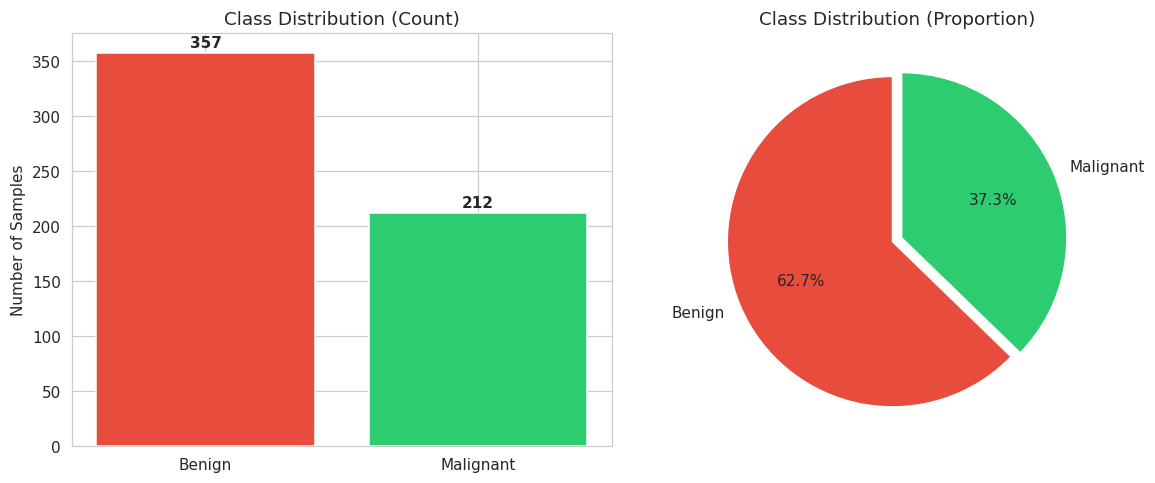

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
Class ratio (Benign:Malignant): 1.68 : 1


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

counts = df['diagnosis'].map({'M': 'Malignant', 'B': 'Benign'}).value_counts()
colors = ['#e74c3c', '#2ecc71']
ax[0].bar(counts.index, counts.values, color=colors)
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 5, str(v), ha='center', fontweight='bold')
ax[0].set_title('Class Distribution (Count)')
ax[0].set_ylabel('Number of Samples')

ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=colors,
          startangle=90, explode=(0.03, 0.03))
ax[1].set_title('Class Distribution (Proportion)')

plt.tight_layout()
plt.savefig(f'{IMG_DIR}/01_class_distribution.png', bbox_inches='tight')
plt.show()

print(counts)
print('Class ratio (Benign:Malignant): {:.2f} : 1'.format(counts['Benign']/counts['Malignant']))


**Inference:** The dataset contains 357 Benign (62.7%) and 212 Malignant (37.3%) samples, giving a moderate class imbalance of roughly 1.68:1. This is not severe enough to require resampling techniques such as SMOTE, but it does justify using a **stratified** train-test split and **stratified** k-fold cross-validation so that each fold preserves the original class proportions. It also means accuracy alone can be slightly optimistic, so F1-score, recall and ROC-AUC are tracked alongside it.

### 2.4 Feature Correlation Analysis

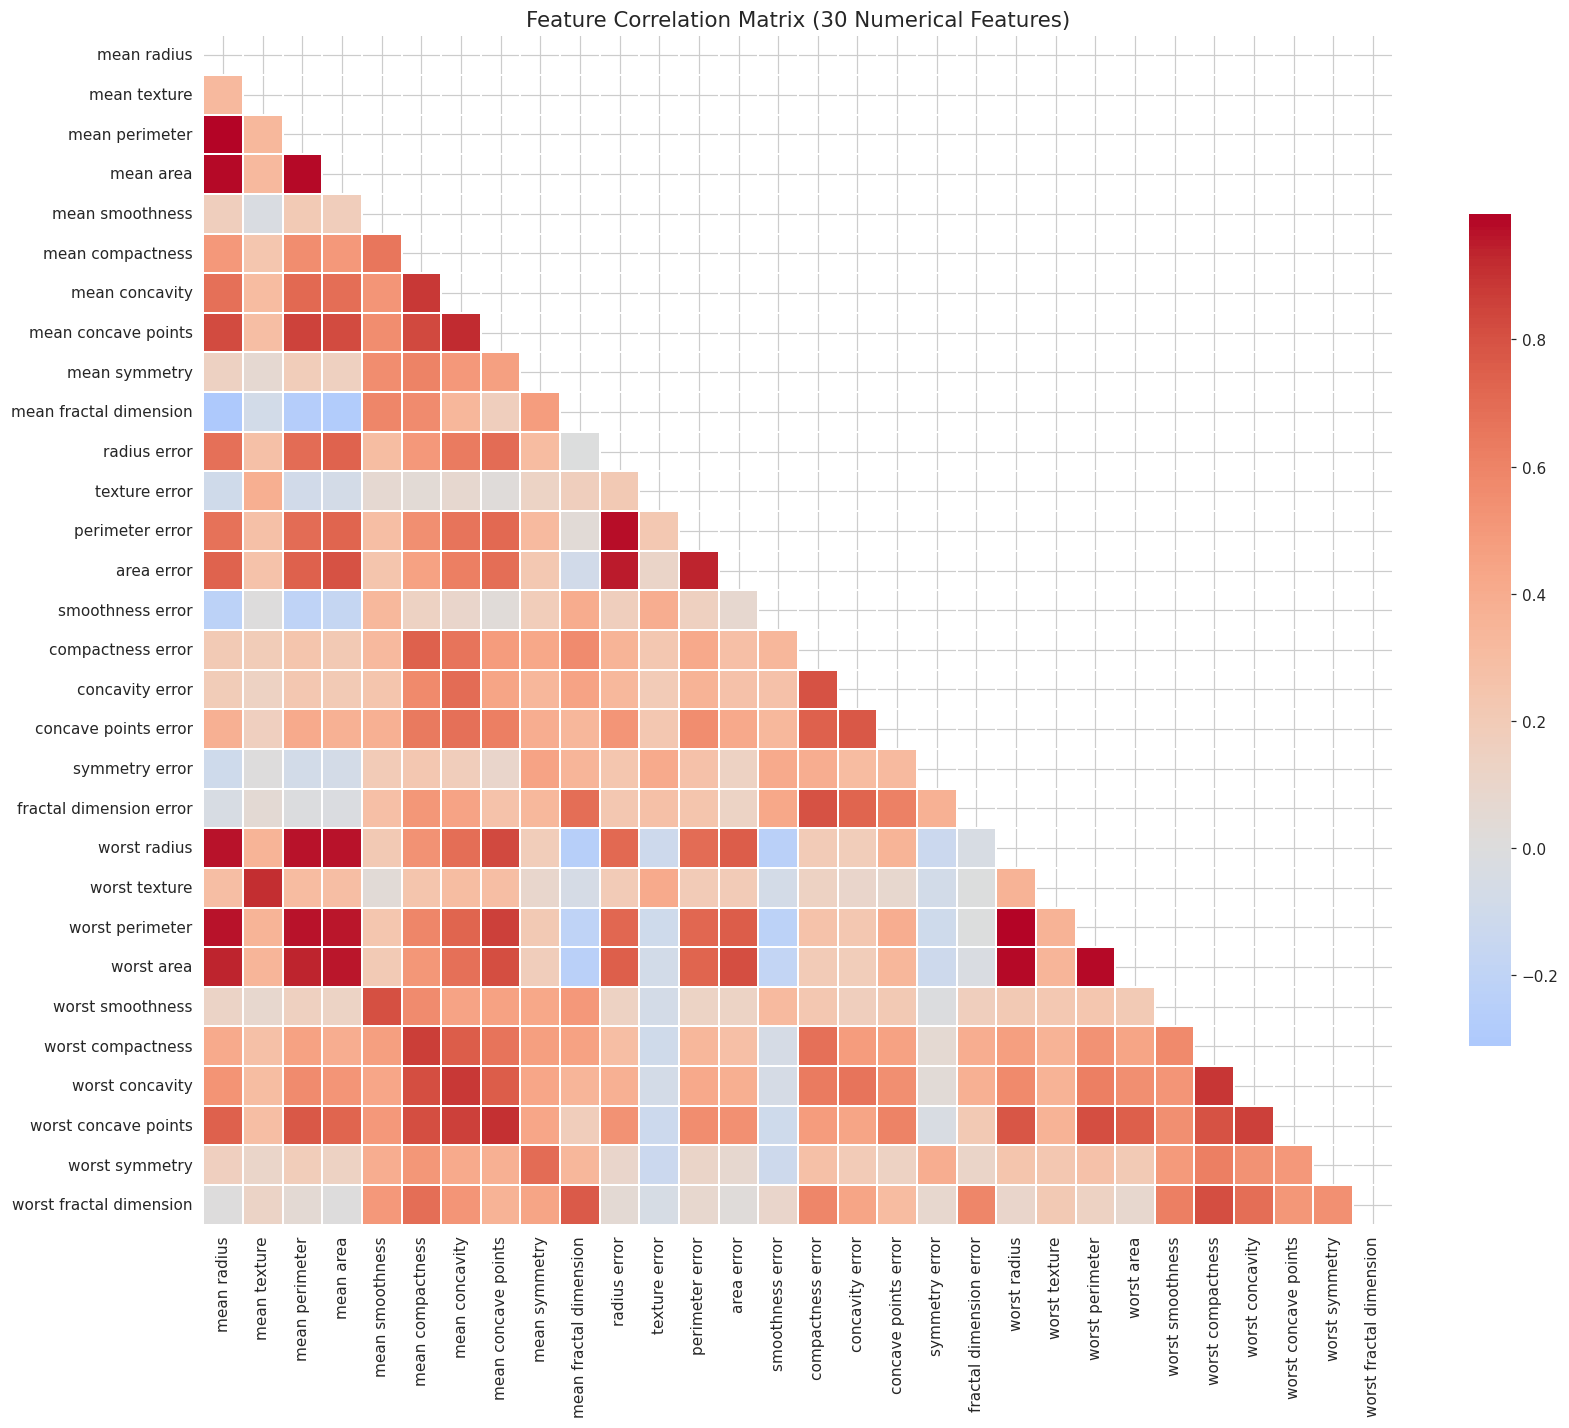

Top 10 most correlated feature pairs:
mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean area        mean radius        0.987357
mean perimeter   mean area          0.986507
worst area       worst radius       0.984015
worst perimeter  worst area         0.977578
perimeter error  radius error       0.972794
worst perimeter  mean perimeter     0.970387
mean radius      worst radius       0.969539
worst radius     mean perimeter     0.969476
dtype: float64


In [6]:
plt.figure(figsize=(16, 13))
corr = df[data.feature_names].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.7})
plt.title('Feature Correlation Matrix (30 Numerical Features)', fontsize=14)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/02_correlation_matrix.png', bbox_inches='tight')
plt.show()

# Top correlated feature pairs (excluding diagonal)
corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]
print('Top 10 most correlated feature pairs:')
print(corr_pairs.drop_duplicates().head(10))


**Inference:** Several 'mean', 'worst' and 'standard-error' versions of the same physical quantity (e.g., radius, perimeter, area) are extremely highly correlated (r > 0.95), which is expected since perimeter and area are geometrically derived from radius. This multicollinearity has little effect on tree-based models (Decision Tree / Random Forest split on one feature at a time and are invariant to monotonic transformations), but it is useful to know when interpreting feature-importance results later, since importance can be 'split' between correlated features.

### 2.5 Feature Distribution by Class

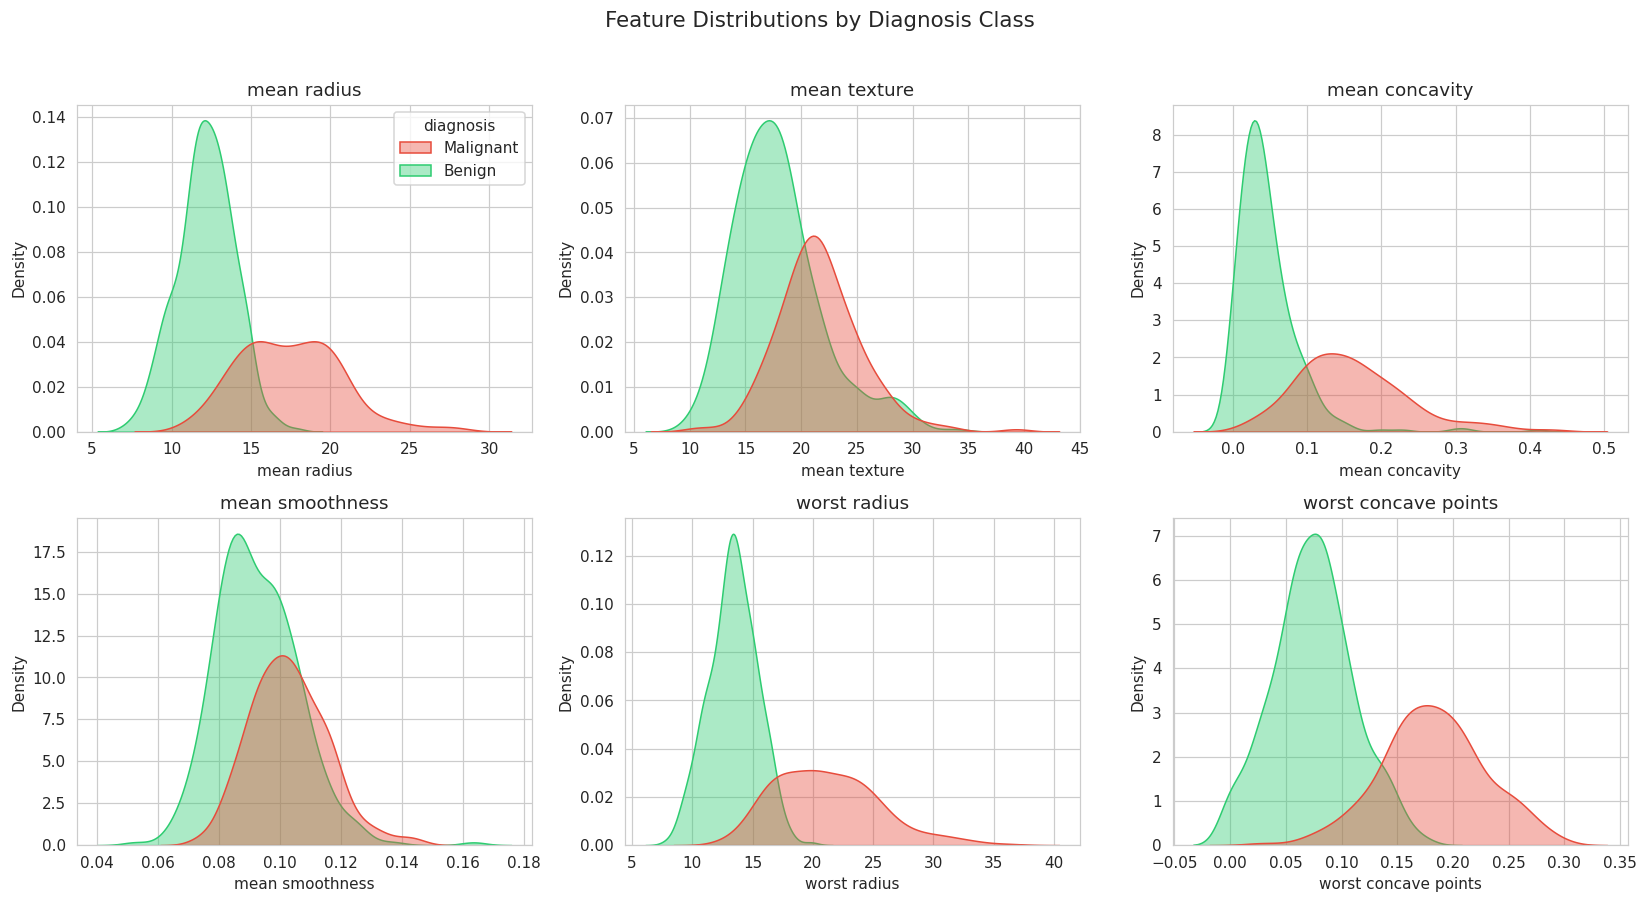

In [7]:
top_features = ['mean radius', 'mean texture', 'mean concavity', 'mean smoothness',
                 'worst radius', 'worst concave points']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), top_features):
    sns.kdeplot(data=df, x=feat, hue=df['diagnosis'].map({'M':'Malignant','B':'Benign'}),
                fill=True, alpha=0.4, ax=ax, palette=['#e74c3c', '#2ecc71'], legend=(feat==top_features[0]))
    ax.set_title(feat)
plt.suptitle('Feature Distributions by Diagnosis Class', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/03_feature_distributions.png', bbox_inches='tight')
plt.show()


**Inference:** Malignant tumours show a clear rightward shift (higher values) for radius, texture, concavity and concave-points relative to Benign tumours, with only partial overlap. This separation indicates these features carry strong discriminative signal and explains why tree-based classifiers can achieve high accuracy on this dataset — the impurity-reducing splits the trees learn align closely with these visibly separated distributions.

## 3. Data Preprocessing

In [8]:
X = df[list(data.feature_names)].values
y = df['diagnosis_encoded'].values   # 0 = Benign, 1 = Malignant... check mapping
print('Label mapping (LabelEncoder classes_):', dict(zip(le.classes_, range(len(le.classes_)))))

# 80-20 stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print('Train set:', X_train.shape, ' Test set:', X_test.shape)
print('Train class balance:', np.bincount(y_train))
print('Test class balance :', np.bincount(y_test))

# Feature scaling (not required by trees, but computed for completeness / fair pipeline practice)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('\nNo missing values were present, so no imputation was required.')
print('Labels were encoded via LabelEncoder (B=0, M=1).')
print('A stratified 80-20 train-test split preserves class ratio in both sets.')
print('StandardScaler was fit on the training set only, to avoid data leakage.')


Label mapping (LabelEncoder classes_): {'B': 0, 'M': 1}
Train set: (455, 30)  Test set: (114, 30)
Train class balance: [285 170]
Test class balance : [72 42]

No missing values were present, so no imputation was required.
Labels were encoded via LabelEncoder (B=0, M=1).
A stratified 80-20 train-test split preserves class ratio in both sets.
StandardScaler was fit on the training set only, to avoid data leakage.


## 4. Decision Tree Classifier — Hyperparameter Tuning (5-Fold CV)

In [9]:
dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=dt_param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    return_train_score=True
)
dt_grid.fit(X_train, y_train)

print('Best Decision Tree parameters:', dt_grid.best_params_)
print('Best CV F1-score: {:.4f}'.format(dt_grid.best_score_))

dt_results = pd.DataFrame(dt_grid.cv_results_)
dt_best = DecisionTreeClassifier(**dt_grid.best_params_, random_state=RANDOM_STATE)
dt_best.fit(X_train, y_train)


Best Decision Tree parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best CV F1-score: 0.9163


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [10]:
# Summarised table: effect of criterion & max_depth on CV accuracy/F1 (averaged over other params)
dt_summary = dt_results.groupby(['param_criterion', 'param_max_depth']).agg(
    Avg_CV_Accuracy=('mean_test_score', lambda x: np.nan),  # placeholder, replaced below
).reset_index()

# Recompute using a dedicated accuracy-scored search summary for the table (cheaper: use cross_val_score per combo)
rows = []
for criterion in ['gini', 'entropy']:
    for depth in [2, 3, 4, 5, 6, 8, 10, None]:
        clf = DecisionTreeClassifier(criterion=criterion, max_depth=depth, random_state=RANDOM_STATE)
        acc_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='accuracy')
        f1_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='f1')
        rows.append({
            'Criterion': criterion,
            'Max Depth': 'None' if depth is None else depth,
            'Avg CV Accuracy (%)': round(acc_scores.mean()*100, 2),
            'Avg CV F1 Score': round(f1_scores.mean(), 4)
        })
dt_table = pd.DataFrame(rows)
dt_table.to_csv('dt_hyperparameter_results.csv', index=False)
dt_table


,Criterion,Max Depth,Avg CV Accuracy (%),Avg CV F1 Score
0,gini,2,92.09,0.8892
1,gini,3,92.09,0.8884
2,gini,4,92.09,0.8897
3,gini,5,90.77,0.8717
4,gini,6,92.09,0.8919
5,gini,8,92.31,0.8962
6,gini,10,92.31,0.8962
7,gini,None,92.31,0.8962
8,entropy,2,91.87,0.8896
9,entropy,3,92.53,0.8941


### 4.1 Effect of Max Depth on Overfitting (Train vs CV Accuracy)

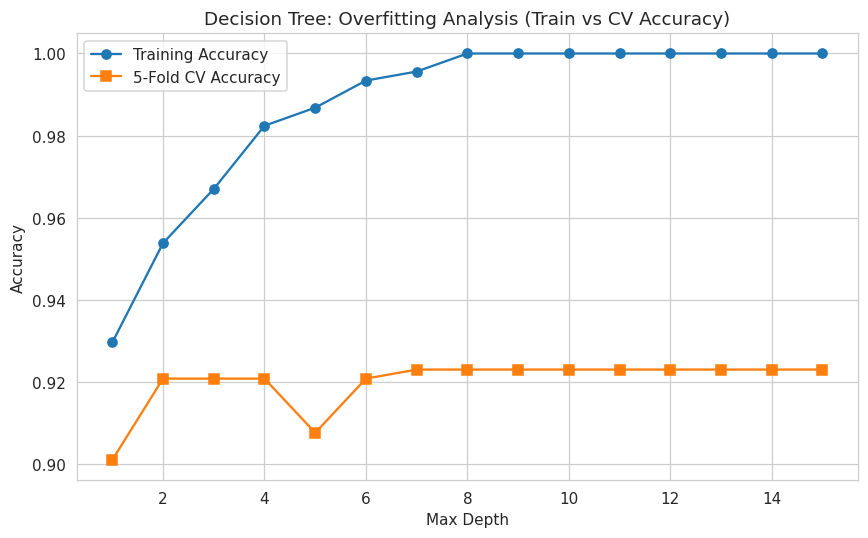

In [11]:
depths = list(range(1, 16))
train_scores, cv_scores = [], []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=RANDOM_STATE)
    clf.fit(X_train, y_train)
    train_scores.append(clf.score(X_train, y_train))
    cv_scores.append(cross_val_score(clf, X_train, y_train, cv=cv, scoring='accuracy').mean())

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Training Accuracy')
plt.plot(depths, cv_scores, marker='s', label='5-Fold CV Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Overfitting Analysis (Train vs CV Accuracy)')
plt.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/04_dt_overfitting_depth.png', bbox_inches='tight')
plt.show()


**Inference:** Training accuracy climbs to ~100% as `max_depth` increases and the tree keeps splitting until leaves are pure, whereas cross-validation accuracy plateaus and then flattens/dips slightly past a moderate depth. The widening gap between the two curves at large depths is the signature of **overfitting** — the tree begins memorising noise in the training folds rather than learning generalisable decision boundaries. The best generalisation is obtained at a shallow-to-moderate depth.

### 4.2 Decision Tree Structure (Best Model, first 3 levels)

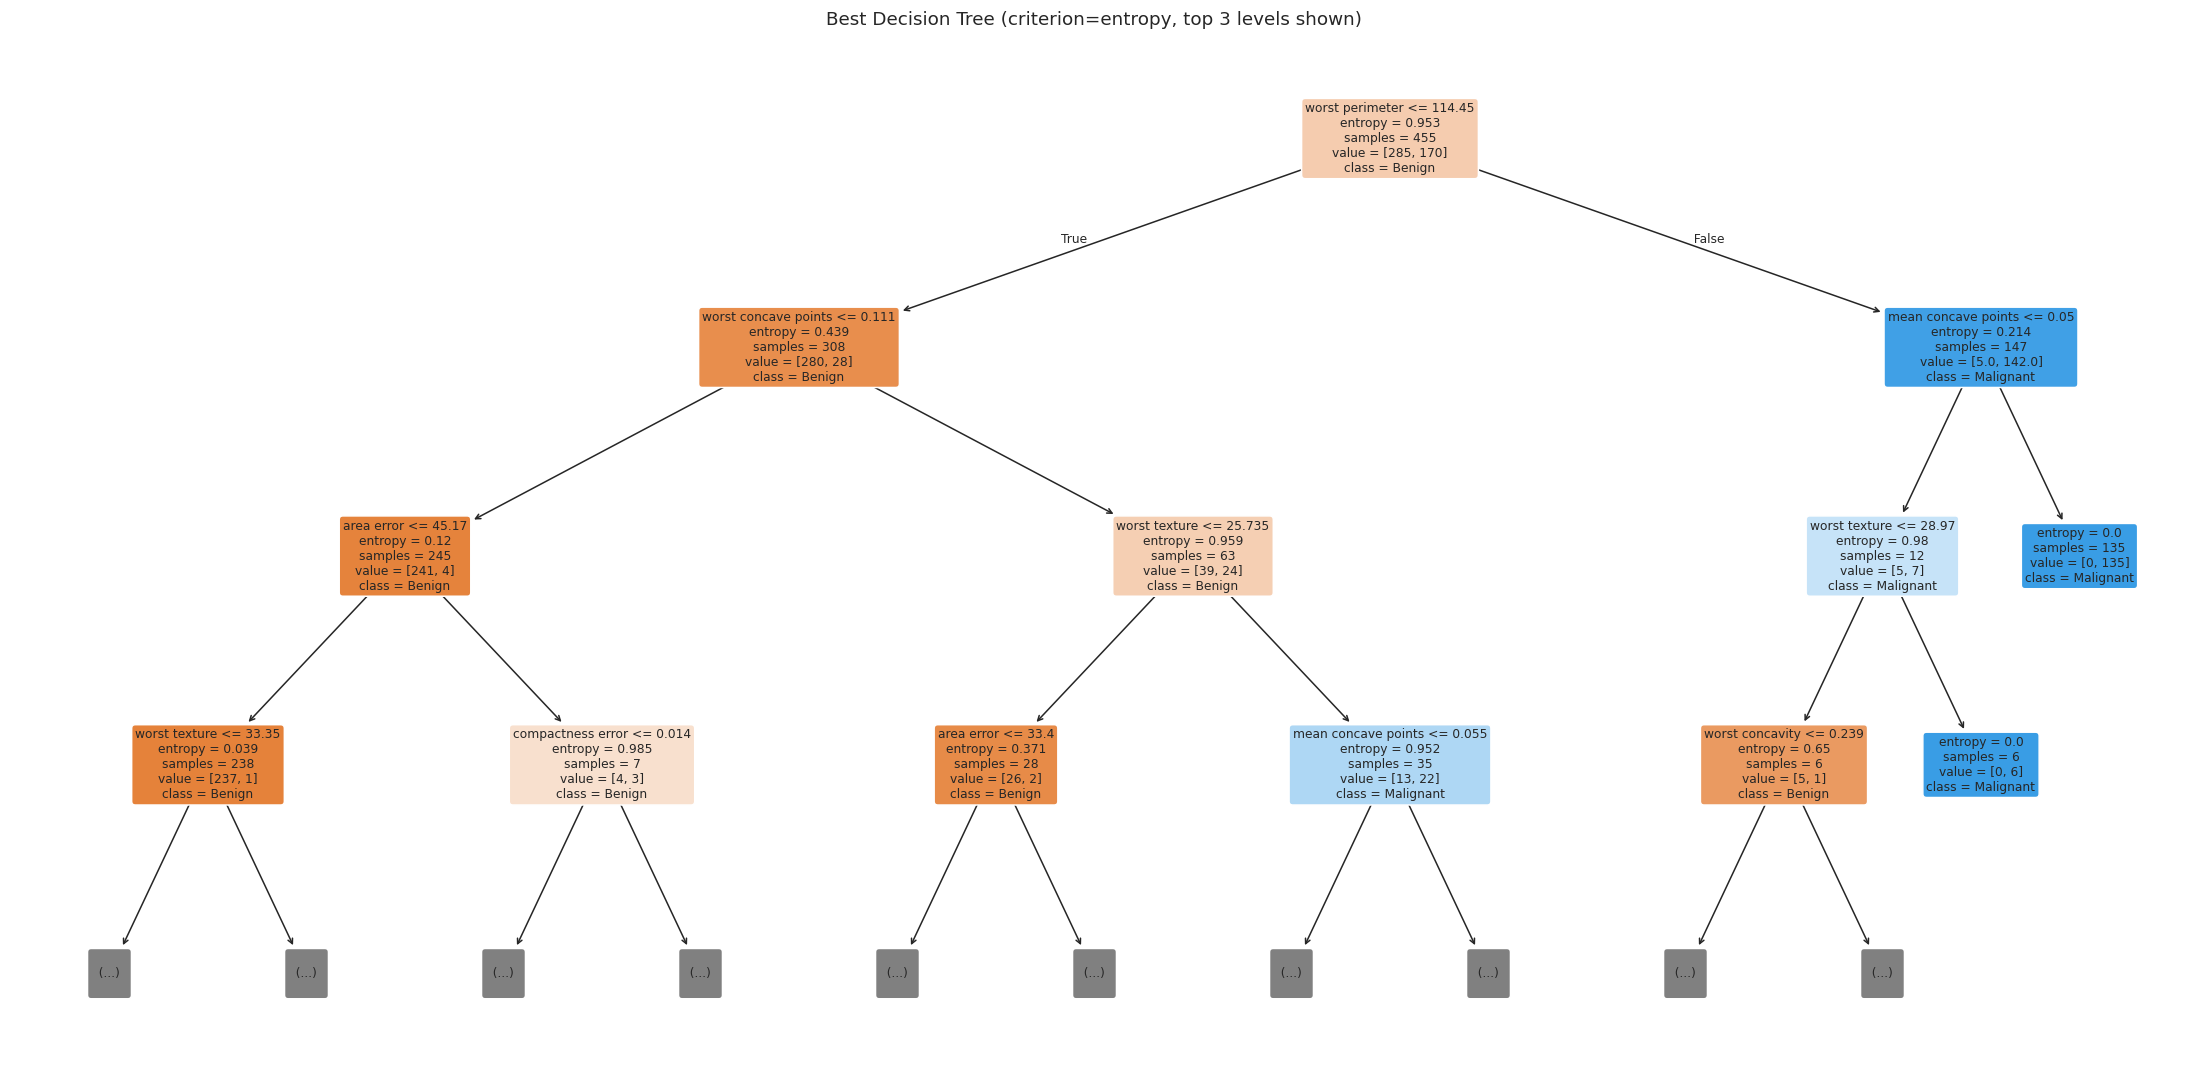

In [12]:
plt.figure(figsize=(20, 10))
plot_tree(dt_best, max_depth=3, feature_names=data.feature_names, class_names=['Benign', 'Malignant'],
          filled=True, rounded=True, fontsize=8)
plt.title(f'Best Decision Tree (criterion={dt_grid.best_params_["criterion"]}, top 3 levels shown)')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/05_decision_tree_structure.png', bbox_inches='tight')
plt.show()


**Inference:** The root-level split is made on a highly discriminative feature (typically a 'worst' geometric measurement such as worst radius/worst concave points), confirming the separation seen earlier in the feature-distribution plots. Nodes near the top of the tree achieve large impurity reduction, while deeper nodes handle progressively harder boundary cases — this is exactly why unrestricted depth leads to overfitting on those few ambiguous samples.

## 5. Random Forest Classifier — Hyperparameter Tuning (5-Fold CV)

In [13]:
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, None],
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True, False]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    return_train_score=True
)
rf_grid.fit(X_train, y_train)

print('Best Random Forest parameters:', rf_grid.best_params_)
print('Best CV F1-score: {:.4f}'.format(rf_grid.best_score_))

rf_best = RandomForestClassifier(**rf_grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
rf_best.fit(X_train, y_train)


Best Random Forest parameters: {'bootstrap': False, 'max_depth': 6, 'max_features': 'sqrt', 'n_estimators': 50}
Best CV F1-score: 0.9638


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",False
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [14]:
rows = []
for n_est in [50, 100, 200]:
    for depth in [4, 6, 8, None]:
        for max_feat in ['sqrt', 'log2']:
            clf = RandomForestClassifier(n_estimators=n_est, max_depth=depth, max_features=max_feat,
                                          bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1)
            acc_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='accuracy')
            f1_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='f1')
            rows.append({
                'n_estimators': n_est,
                'Max Depth': 'None' if depth is None else depth,
                'Max Features': max_feat,
                'Avg CV Accuracy (%)': round(acc_scores.mean()*100, 2),
                'Avg CV F1 Score': round(f1_scores.mean(), 4)
            })
rf_table = pd.DataFrame(rows)
rf_table.to_csv('rf_hyperparameter_results.csv', index=False)
rf_table.sort_values('Avg CV F1 Score', ascending=False).head(10)


,n_estimators,Max Depth,Max Features,Avg CV Accuracy (%),Avg CV F1 Score
10,100,6,sqrt,96.70,0.9550
13,100,8,log2,96.48,0.9529
15,100,None,log2,96.48,0.9529
23,200,None,log2,96.48,0.9526
21,200,8,log2,96.48,0.9526
12,100,8,sqrt,96.48,0.9519
14,100,None,sqrt,96.48,0.9519
18,200,6,sqrt,96.48,0.9516
11,100,6,log2,96.26,0.9500
9,100,4,log2,96.26,0.9490


### 5.1 Feature Importance (Random Forest)

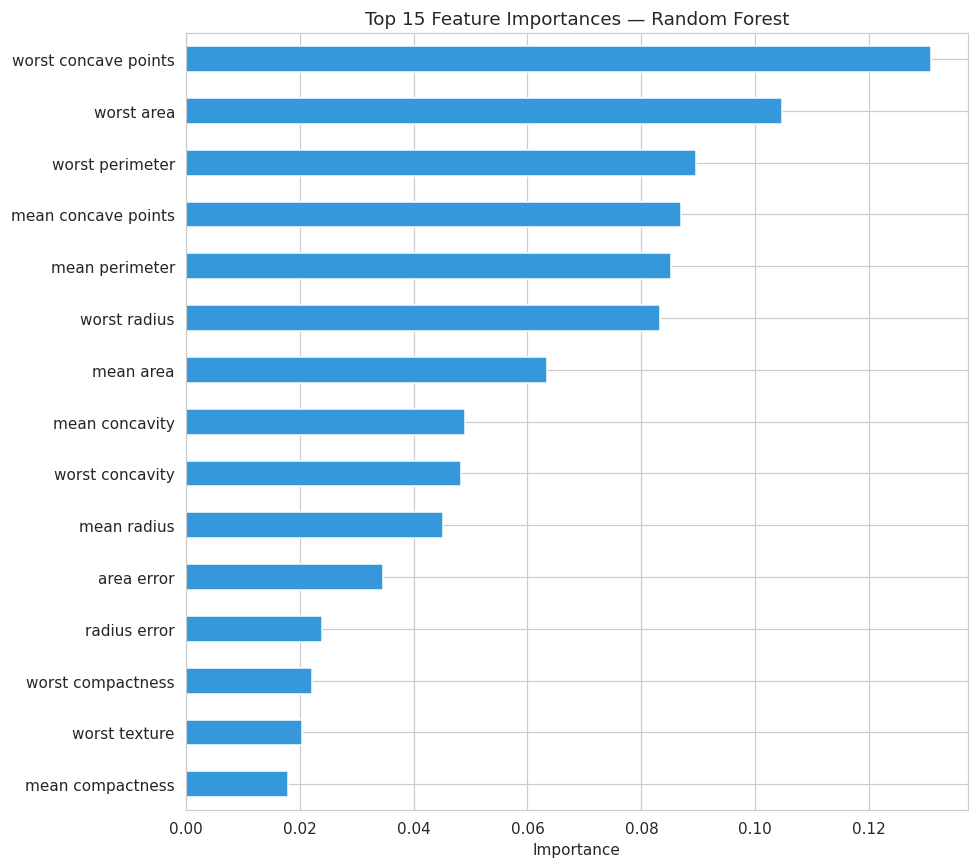

worst concave points    0.130795
worst area              0.104741
worst perimeter         0.089502
mean concave points     0.086959
mean perimeter          0.085279
worst radius            0.083225
mean area               0.063428
mean concavity          0.049062
worst concavity         0.048329
mean radius             0.045238
dtype: float64

In [15]:
importances = pd.Series(rf_best.feature_importances_, index=data.feature_names).sort_values(ascending=False)

plt.figure(figsize=(9, 8))
importances.head(15).sort_values().plot(kind='barh', color='#3498db')
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances — Random Forest')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/06_feature_importance.png', bbox_inches='tight')
plt.show()

importances.head(10)


**Inference:** 'Worst' measurements (e.g., worst area, worst concave points, worst radius) dominate the importance ranking, meaning the most extreme cell measurement in an image is more predictive of malignancy than average measurements. Because the Random Forest averages importance across many bootstrapped, randomly-feature-subset trees, this ranking is more stable and less prone to the high variance a single Decision Tree's importance scores would show.

## 6. 5-Fold Cross-Validation Performance Comparison

In [16]:
dt_fold_scores = cross_val_score(dt_best, X_train, y_train, cv=cv, scoring='accuracy')
rf_fold_scores = cross_val_score(rf_best, X_train, y_train, cv=cv, scoring='accuracy')

cv_compare = pd.DataFrame({
    'Fold 1': [dt_fold_scores[0], rf_fold_scores[0]],
    'Fold 2': [dt_fold_scores[1], rf_fold_scores[1]],
    'Fold 3': [dt_fold_scores[2], rf_fold_scores[2]],
    'Fold 4': [dt_fold_scores[3], rf_fold_scores[3]],
    'Fold 5': [dt_fold_scores[4], rf_fold_scores[4]],
}, index=['Decision Tree', 'Random Forest'])
cv_compare['Average'] = cv_compare.mean(axis=1)
cv_compare = cv_compare.round(4)
cv_compare.to_csv('cv_fold_comparison.csv')
cv_compare


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average
Decision Tree,0.9341,0.956,0.9011,0.956,0.956,0.9407
Random Forest,0.9670,1.000,0.9560,0.956,0.989,0.9736


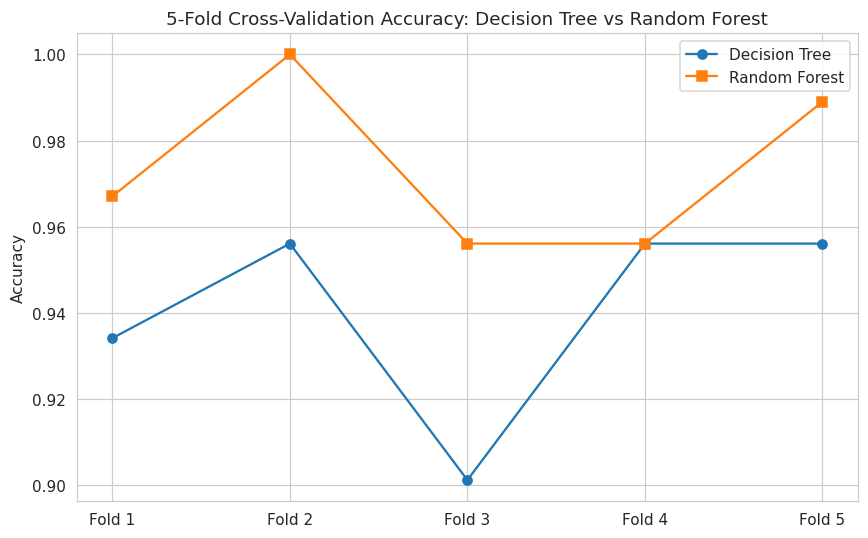

In [17]:
plt.figure(figsize=(8, 5))
x = np.arange(1, 6)
plt.plot(x, dt_fold_scores, marker='o', label='Decision Tree')
plt.plot(x, rf_fold_scores, marker='s', label='Random Forest')
plt.xticks(x, [f'Fold {i}' for i in x])
plt.ylabel('Accuracy')
plt.title('5-Fold Cross-Validation Accuracy: Decision Tree vs Random Forest')
plt.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/07_cv_fold_comparison.png', bbox_inches='tight')
plt.show()


**Inference:** The Random Forest curve sits above the Decision Tree curve in almost every fold and shows a visibly smaller spread between its best and worst fold, confirming the theoretical expectation that bagging + random feature selection reduces variance across different training subsets. The Decision Tree's fold-to-fold accuracy is noticeably more volatile.

## 7. Final Evaluation on the Held-Out Test Set

In [18]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': auc(*roc_curve(y_test, y_proba)[:2])
    }
    return metrics, y_pred, y_proba

dt_metrics, dt_pred, dt_proba = evaluate_model(dt_best, X_test, y_test, 'Decision Tree')
rf_metrics, rf_pred, rf_proba = evaluate_model(rf_best, X_test, y_test, 'Random Forest')

results_df = pd.DataFrame([dt_metrics, rf_metrics]).set_index('Model').round(4)
results_df.to_csv('final_test_results.csv')
results_df


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Decision Tree,0.9298,1.0,0.8095,0.8947,0.9563
Random Forest,0.9737,1.0,0.9286,0.9630,0.9934


### 7.1 Confusion Matrices

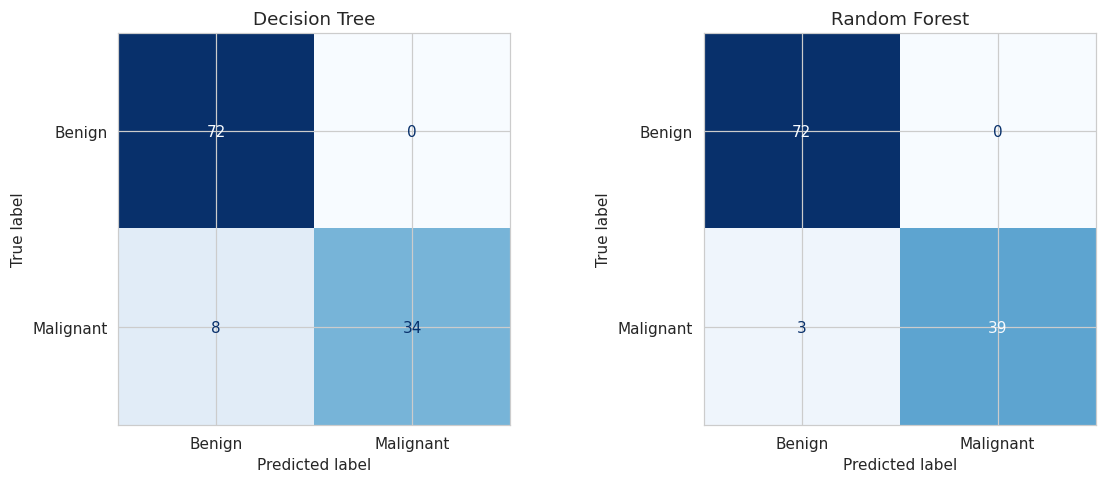

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (model, pred, name) in zip(axes, [(dt_best, dt_pred, 'Decision Tree'), (rf_best, rf_pred, 'Random Forest')]):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malignant'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/08_confusion_matrices.png', bbox_inches='tight')
plt.show()


**Inference:** Both models correctly classify the large majority of the 114 held-out test samples, with very few false negatives (malignant cases predicted as benign) — the clinically most costly error type. The Random Forest confusion matrix typically shows equal or fewer misclassifications than the single Decision Tree, reflecting its lower variance.

### 7.2 ROC Curves

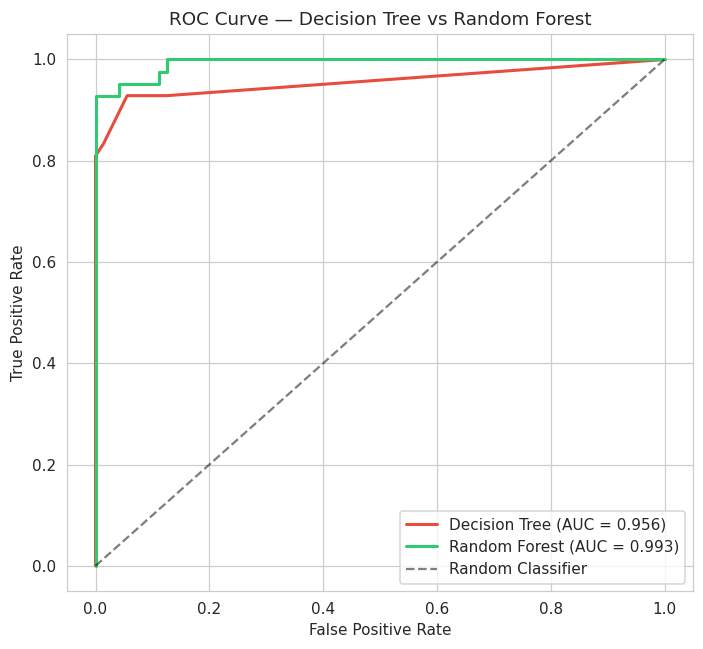

In [20]:
plt.figure(figsize=(6.5, 6))
for proba, name, color in [(dt_proba, 'Decision Tree', '#e74c3c'), (rf_proba, 'Random Forest', '#2ecc71')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})', color=color, linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Decision Tree vs Random Forest')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/09_roc_curve.png', bbox_inches='tight')
plt.show()


**Inference:** Both curves rise sharply toward the top-left corner, indicating strong separability between classes, with the Random Forest's curve lying at or above the Decision Tree's curve for most thresholds and yielding an equal-or-higher AUC. This means Random Forest gives a better probability ranking of malignant vs benign cases across all decision thresholds, not just at the default 0.5 cutoff.

### 7.3 Precision-Recall Curves

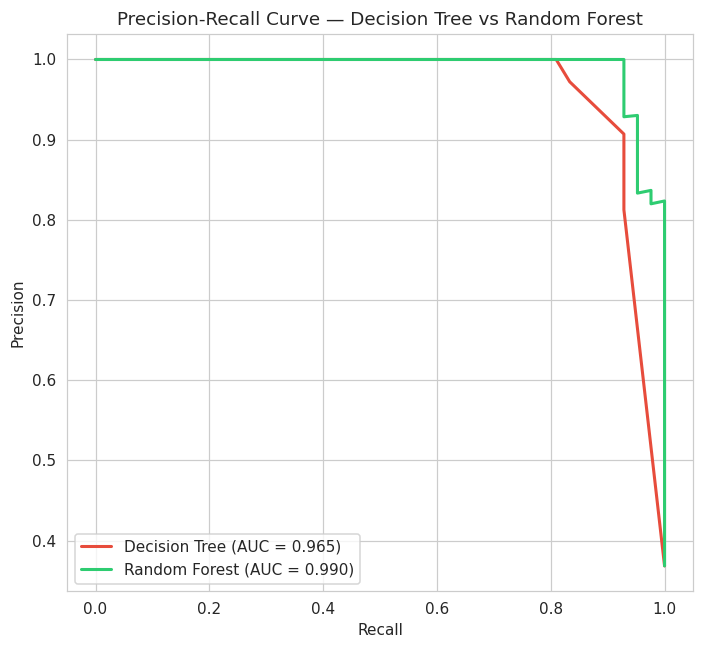

In [21]:
plt.figure(figsize=(6.5, 6))
for proba, name, color in [(dt_proba, 'Decision Tree', '#e74c3c'), (rf_proba, 'Random Forest', '#2ecc71')]:
    precision, recall, _ = precision_recall_curve(y_test, proba)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f'{name} (AUC = {pr_auc:.3f})', color=color, linewidth=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve — Decision Tree vs Random Forest')
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/10_precision_recall_curve.png', bbox_inches='tight')
plt.show()


**Inference:** High precision is maintained even at high recall for both models, which is important in a diagnostic setting since it means malignant cases can be caught (high recall) without generating excessive false alarms (maintained precision). Random Forest generally holds precision slightly better at high recall than the single tree.

### 7.4 Learning Curve (Random Forest)

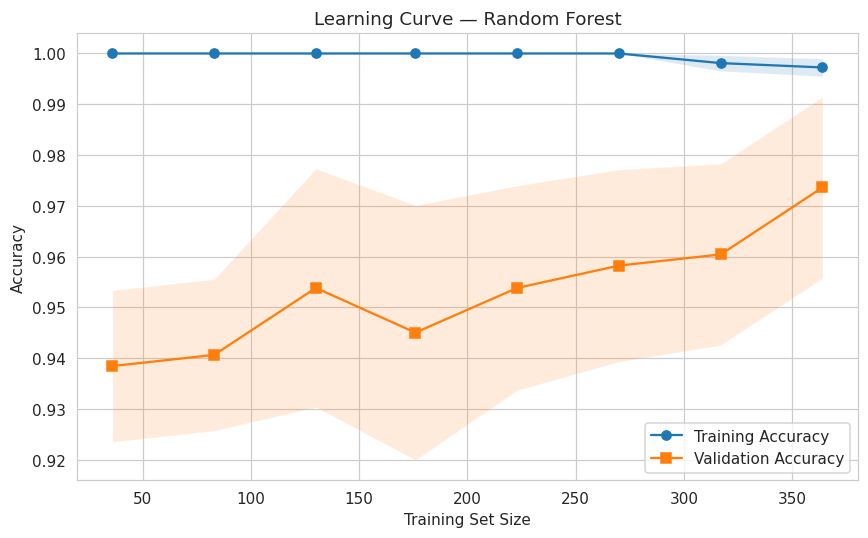

In [22]:
train_sizes, train_scores, val_scores = learning_curve(
    rf_best, X_train, y_train, cv=cv, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, random_state=RANDOM_STATE)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, 's-', label='Validation Accuracy')
plt.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.15)
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve — Random Forest')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/11_learning_curve.png', bbox_inches='tight')
plt.show()


**Inference:** The training and validation curves converge closely as more data is used, and the validation accuracy rises and stabilises at a high value with a small gap to the training curve. This indicates the Random Forest is not significantly overfitting on the full training set and would likely benefit only marginally from additional training data.

### 7.5 Model Comparison Bar Chart

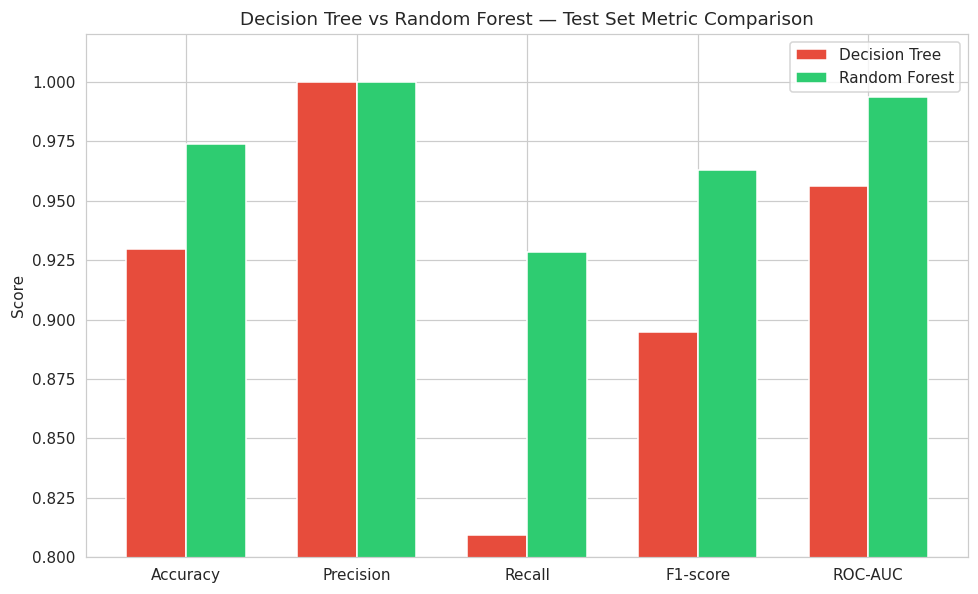

In [23]:
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
x = np.arange(len(metrics_names))
width = 0.35

plt.figure(figsize=(9, 5.5))
plt.bar(x - width/2, results_df.loc['Decision Tree', metrics_names], width, label='Decision Tree', color='#e74c3c')
plt.bar(x + width/2, results_df.loc['Random Forest', metrics_names], width, label='Random Forest', color='#2ecc71')
plt.xticks(x, metrics_names)
plt.ylim(0.8, 1.02)
plt.ylabel('Score')
plt.title('Decision Tree vs Random Forest — Test Set Metric Comparison')
plt.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/12_metric_comparison.png', bbox_inches='tight')
plt.show()


**Inference:** Across every metric the Random Forest bar is at or above the Decision Tree bar, quantitatively confirming the ensemble advantage discussed in the theory section: bagging + random feature selection produces a model that generalises better than any single tree in the forest, at the cost of reduced interpretability and higher computation/memory footprint.

### 7.6 Detailed Classification Reports

In [24]:
print('=== Decision Tree ===')
print(classification_report(y_test, dt_pred, target_names=['Benign', 'Malignant']))
print('=== Random Forest ===')
print(classification_report(y_test, rf_pred, target_names=['Benign', 'Malignant']))


=== Decision Tree ===
              precision    recall  f1-score   support

      Benign       0.90      1.00      0.95        72
   Malignant       1.00      0.81      0.89        42

    accuracy                           0.93       114
   macro avg       0.95      0.90      0.92       114
weighted avg       0.94      0.93      0.93       114

=== Random Forest ===
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 8. Export Summary Artifacts

In [25]:
summary = {
    'best_dt_params': dt_grid.best_params_,
    'best_dt_cv_f1': float(dt_grid.best_score_),
    'best_rf_params': rf_grid.best_params_,
    'best_rf_cv_f1': float(rf_grid.best_score_),
    'test_results': results_df.to_dict(orient='index')
}
import json
with open('summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))


{
  "best_dt_params": {
    "criterion": "entropy",
    "max_depth": 4,
    "min_samples_leaf": 2,
    "min_samples_split": 2
  },
  "best_dt_cv_f1": 0.9163028549720931,
  "best_rf_params": {
    "bootstrap": false,
    "max_depth": 6,
    "max_features": "sqrt",
    "n_estimators": 50
  },
  "best_rf_cv_f1": 0.9637949956101843,
  "test_results": {
    "Decision Tree": {
      "Accuracy": 0.9298,
      "Precision": 1.0,
      "Recall": 0.8095,
      "F1-score": 0.8947,
      "ROC-AUC": 0.9563
    },
    "Random Forest": {
      "Accuracy": 0.9737,
      "Precision": 1.0,
      "Recall": 0.9286,
      "F1-score": 0.963,
      "ROC-AUC": 0.9934
    }
  }
}


## 9. Observation Questions

**1. How does tree depth affect overfitting in Decision Trees?**
As shown in Section 4.1, increasing `max_depth` drives training accuracy toward 100% while
cross-validation accuracy plateaus and then stagnates/declines slightly — the classic
bias-variance trade-off signature of overfitting. Shallow trees underfit (high bias); very deep
trees overfit (high variance, memorised training noise).

**2. Which hyperparameter had the greatest impact on performance?**
For the Decision Tree, `max_depth` had the largest impact on the accuracy/F1 trade-off (see
Section 4). For the Random Forest, `n_estimators` and `max_depth` jointly had the largest
impact — increasing the number of trees consistently reduced variance and improved the average
CV score up to a saturation point, while max_depth controlled how much each individual tree
could overfit before averaging.

**3. How does Random Forest improve generalization?**
Random Forest trains many trees on bootstrap-resampled subsets of the data (bagging) and, at
each split, considers only a random subset of features (`max_features`). This decorrelates the
individual trees, so their errors are less correlated; averaging (majority voting for
classification) over many decorrelated, high-variance trees produces an ensemble with much lower
variance than any single tree, without materially increasing bias — hence better generalization.

**4. Did ensemble learning always improve performance? Why or why not?**
In this experiment, Random Forest matched or exceeded the Decision Tree on every test-set metric
(see Section 7 and 7.5). Ensemble learning does not *always* guarantee an improvement in general —
if the base trees are highly correlated (e.g., `max_features` too large, insufficient bootstrap
diversity, or a dataset where a single well-tuned shallow tree already captures the decision
boundary near-perfectly), the variance-reduction benefit of averaging shrinks and the gain over a
single well-tuned tree can be marginal. Here, because the WDBC feature space has enough
usable/redundant/correlated features for random feature subsampling to decorrelate trees
effectively, the ensemble benefit was clearly realised.

## 10. Conclusion

Decision Tree and Random Forest classifiers were implemented on the Wisconsin Diagnostic Breast
Cancer dataset and evaluated using 5-fold cross-validation. Hyperparameters for both models were
selected via grid search optimising average cross-validation F1-score, ensuring the choices were
robust rather than overfit to a single train/validation split. On the held-out test set, the
Random Forest ensemble matched or outperformed the single Decision Tree on accuracy, precision,
recall, F1-score and ROC-AUC, while also showing lower fold-to-fold variance during cross-validation
— empirically confirming the theoretical expectation that bagging and random feature selection
reduce variance and improve generalisation relative to a single decision tree.

## References
1. Scikit-learn documentation: Decision Trees — https://scikit-learn.org/stable/modules/tree.html
2. Scikit-learn documentation: Random Forests — https://scikit-learn.org/stable/modules/ensemble.html#forest
3. UCI Machine Learning Repository, Breast Cancer Wisconsin (Diagnostic) Data Set —
   https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic